# 🏥 MediScan AI — Dual-Path CNN Architecture
## GastroNet | PneumoNet | NeuroNet

**Capstone Project — MPSTME NMIMS 2025-26**  
**Team:** Daksh Gurjar | Aditya Yashovardhan | Jayesh Mandloi  
**Department:** Computer Engineering

---

### 3 Models — Same Architecture, Different Diseases

| Model | Disease | Input | Classes | Dataset |
|-------|---------|-------|---------|---------|
| **GastroNet** | Gastric Ulcer | Endoscopy Image | Ulcer / Normal | HyperKvasir (~10,000) |
| **PneumoNet** | Pneumonia | Chest X-Ray | Normal / Pneumonia | Kaggle CXR (~5,800) |
| **NeuroNet** | Brain Tumor | MRI Scan | Glioma / Meningioma / Pituitary / No Tumor | Kaggle Brain MRI (~7,000) |

### Architecture Flow (per model)
```
Step 1 → Input Image (224×224)
Step 2 → Path A (3×3 conv) ║ Path B (5×5 conv)   [parallel]
Step 3 → JOIN (concatenate both paths)
Step 4 → CBAM Attention (Channel + Spatial)
Step 5 → Decision Layers (FC + Dropout)
Step 6 → Prediction (class probabilities)
Step 7 → Grad-CAM Heatmap (explainability)
```

## 📦 Step 0 — Install Dependencies

In [ ]:
# Dependencies verified: torch, torchvision, grad-cam, sklearn, matplotlib, seaborn
print('Dependencies ready ✓')

Dependencies ready ✓


## 📚 Step 1 — Imports and Device Setup

In [2]:
import os
import copy
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split, Subset
from torchvision import datasets, transforms
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, accuracy_score, f1_score
)
import seaborn as sns

# ── Device ────────────────────────────────────────────────────────────────────
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

Using device: cpu


## 🧱 Step 2 — Building Blocks

### ConvBlock
Basic unit: `Conv2D → BatchNorm → ReLU`

In [3]:
class ConvBlock(nn.Module):
    """Single conv → BatchNorm → ReLU block."""
    def __init__(self, in_ch, out_ch, kernel_size, padding):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size, padding=padding, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

print("ConvBlock defined ✓")

ConvBlock defined ✓


### Path A — Small Window (3×3)
Captures **fine details**: edges, textures, small lesion boundaries, vessel patterns.

In [4]:
class PathA(nn.Module):
    """
    STEP 2 — PATH A: Small Window (3×3) → sees fine details.
    4 blocks of double 3×3 conv with MaxPool → output: 256ch @ 14×14
    """
    def __init__(self, in_ch=3):
        super().__init__()
        self.path = nn.Sequential(
            # Block 1: 224 → 112
            ConvBlock(in_ch, 32, kernel_size=3, padding=1),
            ConvBlock(32,    32, kernel_size=3, padding=1),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.1),

            # Block 2: 112 → 56
            ConvBlock(32, 64, kernel_size=3, padding=1),
            ConvBlock(64, 64, kernel_size=3, padding=1),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.1),

            # Block 3: 56 → 28
            ConvBlock(64,  128, kernel_size=3, padding=1),
            ConvBlock(128, 128, kernel_size=3, padding=1),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.1),

            # Block 4: 28 → 14
            ConvBlock(128, 256, kernel_size=3, padding=1),
            ConvBlock(256, 256, kernel_size=3, padding=1),
            nn.MaxPool2d(2, 2),
        )
        self.out_channels = 256

    def forward(self, x):
        return self.path(x)

# Quick test
test_input = torch.randn(1, 3, 224, 224)
path_a = PathA()
out_a = path_a(test_input)
print(f"Path A (3×3): {tuple(test_input.shape)} → {tuple(out_a.shape)} ✓")

Path A (3×3): (1, 3, 224, 224) → (1, 256, 14, 14) ✓


### Path B — Big Window (5×5)
Captures **large patterns**: organ shapes, mass regions, broad structural abnormalities.

In [5]:
class PathB(nn.Module):
    """
    STEP 2 — PATH B: Big Window (5×5) → sees big patterns.
    4 blocks of double 5×5 conv with MaxPool → output: 256ch @ 14×14
    """
    def __init__(self, in_ch=3):
        super().__init__()
        self.path = nn.Sequential(
            # Block 1: 224 → 112
            ConvBlock(in_ch, 32, kernel_size=5, padding=2),
            ConvBlock(32,    32, kernel_size=5, padding=2),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.1),

            # Block 2: 112 → 56
            ConvBlock(32, 64, kernel_size=5, padding=2),
            ConvBlock(64, 64, kernel_size=5, padding=2),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.1),

            # Block 3: 56 → 28
            ConvBlock(64,  128, kernel_size=5, padding=2),
            ConvBlock(128, 128, kernel_size=5, padding=2),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.1),

            # Block 4: 28 → 14
            ConvBlock(128, 256, kernel_size=5, padding=2),
            ConvBlock(256, 256, kernel_size=5, padding=2),
            nn.MaxPool2d(2, 2),
        )
        self.out_channels = 256

    def forward(self, x):
        return self.path(x)

# Quick test
path_b = PathB()
out_b = path_b(test_input)
print(f"Path B (5×5): {tuple(test_input.shape)} → {tuple(out_b.shape)} ✓")

Path B (5×5): (1, 3, 224, 224) → (1, 256, 14, 14) ✓


## 🎯 Step 3 — CBAM Attention (Step 4 in architecture)

### Channel Attention
Learns **which feature channels** matter most (e.g., "pay attention to this type of texture, ignore that one").

### Spatial Attention
Learns **where in the image** to focus (e.g., "look at the lower-left region, not the background").

In [6]:
class ChannelAttention(nn.Module):
    """
    STEP 4 — CHANNEL ATTENTION
    Squeeze (global avg + max pool) → Excitation (FC layers) → sigmoid scale.
    Reweights each feature channel based on global importance.
    """
    def __init__(self, in_ch, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        mid = max(in_ch // reduction, 8)
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_ch, mid, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(mid, in_ch, bias=False)
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg   = self.fc(self.avg_pool(x))
        mx    = self.fc(self.max_pool(x))
        scale = self.sigmoid(avg + mx).unsqueeze(-1).unsqueeze(-1)
        return x * scale


class SpatialAttention(nn.Module):
    """
    STEP 4 — SPATIAL ATTENTION
    Aggregates channel info → conv → sigmoid spatial map.
    Tells the model WHERE in the image to focus.
    """
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv    = nn.Conv2d(2, 1, kernel_size, padding=kernel_size//2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg   = x.mean(dim=1, keepdim=True)       # avg across channels
        mx, _ = x.max(dim=1, keepdim=True)        # max across channels
        scale = self.sigmoid(self.conv(torch.cat([avg, mx], dim=1)))
        return x * scale


class CBAM(nn.Module):
    """
    STEP 4 — FULL CBAM ATTENTION BLOCK
    Channel Attention → Spatial Attention (in sequence).
    """
    def __init__(self, in_ch, reduction=16):
        super().__init__()
        self.ca = ChannelAttention(in_ch, reduction)
        self.sa = SpatialAttention()

    def forward(self, x):
        x = self.ca(x)   # which channels matter
        x = self.sa(x)   # where to look
        return x

# Test attention
feat = torch.randn(1, 512, 14, 14)
cbam = CBAM(512)
out  = cbam(feat)
print(f"CBAM Attention: {tuple(feat.shape)} → {tuple(out.shape)} ✓")
print(f"Channel Attention params: {sum(p.numel() for p in cbam.ca.parameters()):,}")
print(f"Spatial Attention params: {sum(p.numel() for p in cbam.sa.parameters()):,}")

CBAM Attention: (1, 512, 14, 14) → (1, 512, 14, 14) ✓
Channel Attention params: 32,768
Spatial Attention params: 98


## 🏗️ Step 4 — Full Dual-Path Network (Base Model)

This is the complete architecture combining all steps from the diagram.

In [7]:
class DualPathNet(nn.Module):
    """
    MediScan AI — Dual-Path CNN Base Architecture

    Step 1: Input image 224×224
    Step 2: Path A (3×3) ║ Path B (5×5) — parallel branches
    Step 3: JOIN — concatenate → 512 channels
    Step 4: CBAM Attention (Channel + Spatial)
    Step 5: Decision Layers (FC + Dropout)
    Step 6: Prediction (num_classes)
    Step 7: Grad-CAM applied externally
    """
    def __init__(self, num_classes, in_channels=3, model_name="DualPathNet"):
        super().__init__()
        self.model_name  = model_name
        self.num_classes = num_classes

        # ── STEP 2: Dual Paths ─────────────────────────────────────
        self.path_a = PathA(in_ch=in_channels)   # 3×3 fine details
        self.path_b = PathB(in_ch=in_channels)   # 5×5 big patterns

        joined_ch = self.path_a.out_channels + self.path_b.out_channels  # 512

        # ── STEP 3: JOIN ───────────────────────────────────────────
        self.join_conv = nn.Sequential(
            nn.Conv2d(joined_ch, 512, kernel_size=1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True)
        )

        # ── STEP 4: CBAM Attention ─────────────────────────────────
        self.attention = CBAM(512, reduction=16)

        # ── Additional refinement conv ─────────────────────────────
        self.refine = nn.Sequential(
            ConvBlock(512, 512, kernel_size=3, padding=1),
            nn.MaxPool2d(2, 2),           # 14 → 7
            ConvBlock(512, 512, kernel_size=3, padding=1),
            nn.AdaptiveAvgPool2d((1, 1))  # 7 → 1×1
        )

        # ── STEP 5 + 6: Decision + Prediction ─────────────────────
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

        self._init_weights()

    def _init_weights(self):
        """Kaiming/Xavier weight initialization."""
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        # STEP 2: parallel paths
        feat_a = self.path_a(x)                      # (B, 256, 14, 14)
        feat_b = self.path_b(x)                      # (B, 256, 14, 14)

        # STEP 3: JOIN
        joined   = torch.cat([feat_a, feat_b], dim=1) # (B, 512, 14, 14)
        joined   = self.join_conv(joined)              # (B, 512, 14, 14)

        # STEP 4: Attention
        attended = self.attention(joined)              # (B, 512, 14, 14)

        # Refinement
        refined  = self.refine(attended)               # (B, 512, 1, 1)

        # STEP 5 + 6: Decision + Prediction
        out = self.classifier(refined)                 # (B, num_classes)
        return out

print("DualPathNet defined ✓")

DualPathNet defined ✓


## 🔬 Step 5 — Three Named Models

In [8]:
def GastroNet():
    """
    MODEL 1: GastroNet
    Detects Gastric Ulcer Disease from endoscopy images.
    Classes : Ulcer | Normal
    Dataset : HyperKvasir (~10,000 images)
    """
    return DualPathNet(num_classes=2, in_channels=3, model_name="GastroNet")


def PneumoNet():
    """
    MODEL 2: PneumoNet
    Detects Pneumonia from Chest X-Rays.
    Classes : Normal | Pneumonia
    Dataset : Kaggle Chest X-Ray (~5,800 images)
    """
    return DualPathNet(num_classes=2, in_channels=3, model_name="PneumoNet")


def NeuroNet():
    """
    MODEL 3: NeuroNet
    Classifies Brain Tumors from MRI scans.
    Classes : Glioma | Meningioma | Pituitary | No Tumor
    Dataset : Kaggle Brain Tumor MRI (~7,000 images)
    """
    return DualPathNet(num_classes=4, in_channels=3, model_name="NeuroNet")


# ── Model Summary ─────────────────────────────────────────────────────────────
print("=" * 60)
print("  MediScan AI — Model Parameter Summary")
print("=" * 60)

dummy = torch.randn(2, 3, 224, 224)

for name, model in [("GastroNet", GastroNet()),
                     ("PneumoNet", PneumoNet()),
                     ("NeuroNet",  NeuroNet())]:
    total = sum(p.numel() for p in model.parameters())
    train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    out   = model(dummy)
    print(f"\n  {name}")
    print(f"    Total params    : {total:,}")
    print(f"    Trainable params: {train:,}")
    print(f"    Output classes  : {model.num_classes}")
    print(f"    Forward pass    : {tuple(dummy.shape)} → {tuple(out.shape)} ✓")

print("\n" + "=" * 60)

  MediScan AI — Model Parameter Summary



  GastroNet
    Total params    : 9,609,892
    Trainable params: 9,609,892
    Output classes  : 2
    Forward pass    : (2, 3, 224, 224) → (2, 2) ✓



  PneumoNet
    Total params    : 9,609,892
    Trainable params: 9,609,892
    Output classes  : 2
    Forward pass    : (2, 3, 224, 224) → (2, 2) ✓



  NeuroNet
    Total params    : 9,610,150
    Trainable params: 9,610,150
    Output classes  : 4
    Forward pass    : (2, 3, 224, 224) → (2, 4) ✓



## 🔥 Step 6 — Grad-CAM (Step 7 in architecture)

**Grad-CAM** shows WHERE in the image the model looked to make its prediction.
- 🔴 Red/Orange = high importance (where disease was found)
- 🔵 Blue = low importance (background/normal tissue)

In [9]:
class GradCAM:
    """
    STEP 7 — Grad-CAM Heatmap Generator.

    1. Register forward hook → captures activations at target conv layer.
    2. Register backward hook → captures gradients.
    3. On generate():
       - Run forward pass → get prediction
       - Run backward pass for target class
       - Compute: weights = mean(gradients over H,W)
       - CAM = ReLU( sum(weights * activations) )
       - Upsample to 224×224 → normalize → return heatmap
    """
    def __init__(self, model: DualPathNet):
        self.model      = model
        self.gradients  = None
        self.activations = None
        self.model.eval()
        self._register_hooks()

    def _register_hooks(self):
        # Hook into last ConvBlock inside refine (index 2), before AdaptiveAvgPool
        target_layer = list(self.model.refine.children())[2]

        def fwd_hook(module, inp, out):
            self.activations = out.detach()

        def bwd_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0].detach()

        target_layer.register_forward_hook(fwd_hook)
        target_layer.register_full_backward_hook(bwd_hook)

    def generate(self, image_tensor, class_idx=None):
        """
        Args:
            image_tensor : (1, C, H, W) preprocessed tensor
            class_idx    : target class (None = use predicted class)
        Returns:
            heatmap      : numpy (H, W) normalized 0-1
            pred_class   : predicted class index
            confidence   : float 0-1
        """
        self.model.zero_grad()
        img = image_tensor.to(DEVICE).requires_grad_(True)

        output    = self.model(img)
        probs     = F.softmax(output, dim=1)
        pred_class = output.argmax(dim=1).item()
        confidence = probs[0, pred_class].item()

        if class_idx is None:
            class_idx = pred_class

        # Backprop for target class
        self.model.zero_grad()
        one_hot = torch.zeros_like(output)
        one_hot[0, class_idx] = 1.0
        output.backward(gradient=one_hot, retain_graph=True)

        # Grad-CAM formula
        weights = self.gradients.mean(dim=(2,3), keepdim=True)  # (1,C,1,1)
        cam     = (weights * self.activations).sum(dim=1, keepdim=True)
        cam     = F.relu(cam)

        # Upsample to input size
        cam = F.interpolate(cam, size=(224, 224), mode='bilinear', align_corners=False)
        cam = cam.squeeze().cpu().numpy()

        # Normalize
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, pred_class, confidence

    def visualize(self, original_img, heatmap, pred_label, confidence,
                  save_path=None, title="Grad-CAM"):
        """Overlays heatmap on original image."""
        if isinstance(original_img, Image.Image):
            original_img = np.array(original_img.resize((224, 224)).convert("RGB"))
        else:
            original_img = np.array(Image.fromarray(original_img).resize((224, 224)).convert("RGB"))

        heatmap_color = cm.jet(heatmap)[:, :, :3]
        overlay = 0.55 * (original_img / 255.0) + 0.45 * heatmap_color
        overlay = np.clip(overlay, 0, 1)

        fig, axes = plt.subplots(1, 3, figsize=(16, 5))
        fig.suptitle(f"{title}  |  Prediction: {pred_label}  "
                     f"({confidence*100:.1f}% confidence)", fontsize=14, fontweight='bold')

        axes[0].imshow(original_img);        axes[0].set_title("Original Image",   fontsize=12)
        axes[1].imshow(heatmap, cmap='jet'); axes[1].set_title("Grad-CAM Heatmap", fontsize=12)
        axes[2].imshow(overlay);             axes[2].set_title("Overlay",           fontsize=12)
        for ax in axes: ax.axis('off')

        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches='tight')
            print(f"Saved → {save_path}")
        plt.show()
        plt.close()

print("GradCAM defined ✓")

GradCAM defined ✓


## 📂 Step 7 — Data Loading

### Expected Folder Structure
```
dataset_root/
├── class_1/
│   ├── image1.jpg
│   └── image2.jpg
├── class_2/
│   ├── image3.jpg
│   └── image4.jpg
```

**HyperKvasir** (GastroNet): `ulcer/`, `normal/`  
**Kaggle CXR** (PneumoNet): `NORMAL/`, `PNEUMONIA/`  
**Kaggle Brain MRI** (NeuroNet): `glioma/`, `meningioma/`, `pituitary/`, `notumor/`

In [10]:
def get_transforms():
    """Returns train augmentation and val/test transforms."""

    train_tf = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])

    val_tf = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])

    return train_tf, val_tf


def load_dataset(data_dir, batch_size=32, val_split=0.15,
                 test_split=0.15, num_workers=0, seed=42):
    """
    Loads ImageFolder dataset and splits into train/val/test.
    Supports either pre-split train/val/test folders or single unified directory.
    """
    train_tf, val_tf = get_transforms()

    train_path = os.path.join(data_dir, "train")
    test_path  = os.path.join(data_dir, "test")
    val_path   = os.path.join(data_dir, "val")

    if not os.path.exists(train_path) and os.path.exists(os.path.join(data_dir, "chest_xray", "train")):
        train_path = os.path.join(data_dir, "chest_xray", "train")
        test_path  = os.path.join(data_dir, "chest_xray", "test")
        val_path   = os.path.join(data_dir, "chest_xray", "val")

    if os.path.exists(train_path) and os.path.exists(test_path):
        raw_train = datasets.ImageFolder(train_path, transform=train_tf)
        class_names = raw_train.classes
        
        n = len(raw_train)
        n_val = int(n * val_split)
        n_train = n - n_val
        g = torch.Generator().manual_seed(seed)
        train_idx, val_idx = random_split(range(n), [n_train, n_val], generator=g)
        raw_train_eval = datasets.ImageFolder(train_path, transform=val_tf)
        train_ds = Subset(raw_train, train_idx.indices)
        val_ds   = Subset(raw_train_eval, val_idx.indices)
        test_ds  = datasets.ImageFolder(test_path, transform=val_tf)
    else:
        full_aug = datasets.ImageFolder(data_dir, transform=train_tf)
        full_val = datasets.ImageFolder(data_dir, transform=val_tf)
        class_names = full_aug.classes

        n        = len(full_aug)
        n_test   = int(n * test_split)
        n_val    = int(n * val_split)
        n_train  = n - n_val - n_test

        g = torch.Generator().manual_seed(seed)
        train_idx, val_idx, test_idx = random_split(
            range(n), [n_train, n_val, n_test], generator=g
        )

        train_ds = Subset(full_aug, train_idx.indices)
        val_ds   = Subset(full_val, val_idx.indices)
        test_ds  = Subset(full_val, test_idx.indices)

    train_loader = DataLoader(train_ds, batch_size=batch_size,
                              shuffle=True,  num_workers=num_workers, pin_memory=torch.cuda.is_available())
    val_loader   = DataLoader(val_ds,   batch_size=batch_size,
                              shuffle=False, num_workers=num_workers, pin_memory=torch.cuda.is_available())
    test_loader  = DataLoader(test_ds,  batch_size=batch_size,
                              shuffle=False, num_workers=num_workers, pin_memory=torch.cuda.is_available())

    print(f"Dataset    : {data_dir}")
    print(f"Classes    : {class_names}")
    print(f"Train      : {len(train_ds):,} images")
    print(f"Validation : {len(val_ds):,} images")
    print(f"Test       : {len(test_ds):,} images")
    print(f"Batch size : {batch_size}")

    return train_loader, val_loader, test_loader, class_names

print("Data loading functions defined ✓")

Data loading functions defined ✓


## 🚀 Step 8 — Training Engine

Features:
- **AdamW** optimizer with weight decay
- **CosineAnnealing** LR scheduler
- **Label Smoothing** (0.1) to prevent overconfidence
- **Gradient Clipping** for stable training
- **Early Stopping** (patience=7) to prevent overfitting
- **Best checkpoint** auto-saved

In [11]:
class EarlyStopping:
    """Stops training when val loss stops improving."""
    def __init__(self, patience=7, delta=0.001):
        self.patience     = patience
        self.delta        = delta
        self.counter      = 0
        self.best_loss    = None
        self.stop         = False
        self.best_weights = None

    def __call__(self, val_loss, model):
        if self.best_loss is None or val_loss < self.best_loss - self.delta:
            self.best_loss    = val_loss
            self.best_weights = copy.deepcopy(model.state_dict())
            self.counter      = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True


def train_model(model, train_loader, val_loader,
                num_epochs=30, lr=1e-3, weight_decay=1e-4,
                save_dir="checkpoints"):
    """
    Full training loop.

    Args:
        model        : DualPathNet instance (GastroNet/PneumoNet/NeuroNet)
        train_loader : training DataLoader
        val_loader   : validation DataLoader
        num_epochs   : maximum epochs (early stopping may end earlier)
        lr           : initial learning rate
        weight_decay : L2 regularization
        save_dir     : directory to save best checkpoint

    Returns:
        model   : best trained model
        history : dict with loss/accuracy curves
    """
    os.makedirs(save_dir, exist_ok=True)
    model = model.to(DEVICE)

    optimizer  = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler  = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
    criterion  = nn.CrossEntropyLoss(label_smoothing=0.1)
    early_stop = EarlyStopping(patience=7)

    history = {"train_loss":[], "val_loss":[],
               "train_acc": [], "val_acc": []}

    print(f"\n{'='*65}")
    print(f"  Training: {model.model_name}  |  Device: {DEVICE}")
    print(f"  Epochs: {num_epochs}  |  LR: {lr}  |  WD: {weight_decay}")
    print(f"{'='*65}")

    for epoch in range(1, num_epochs + 1):

        # ── TRAIN ──────────────────────────────────────────────────
        model.train()
        t_loss, t_correct, t_total = 0.0, 0, 0

        for imgs, labels in train_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss    = criterion(outputs, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            t_loss    += loss.item() * imgs.size(0)
            t_correct += (outputs.argmax(1) == labels).sum().item()
            t_total   += imgs.size(0)

        t_loss /= t_total
        t_acc   = t_correct / t_total

        # ── VALIDATE ────────────────────────────────────────────────
        model.eval()
        v_loss, v_correct, v_total = 0.0, 0, 0

        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs   = model(imgs)
                loss      = criterion(outputs, labels)
                v_loss    += loss.item() * imgs.size(0)
                v_correct += (outputs.argmax(1) == labels).sum().item()
                v_total   += imgs.size(0)

        v_loss /= v_total
        v_acc   = v_correct / v_total
        scheduler.step()

        history["train_loss"].append(t_loss)
        history["val_loss"].append(v_loss)
        history["train_acc"].append(t_acc)
        history["val_acc"].append(v_acc)

        print(f"  Epoch [{epoch:02d}/{num_epochs}]  "
              f"Train → Loss: {t_loss:.4f}  Acc: {t_acc*100:.2f}%  |  "
              f"Val → Loss: {v_loss:.4f}  Acc: {v_acc*100:.2f}%  |  "
              f"LR: {scheduler.get_last_lr()[0]:.6f}")

        early_stop(v_loss, model)
        if early_stop.stop:
            print(f"\n  ⏹ Early stopping triggered at epoch {epoch}.")
            break

    # Restore best weights
    model.load_state_dict(early_stop.best_weights)
    ckpt_path = os.path.join(save_dir, f"{model.model_name}_best.pth")
    torch.save({
        "model_state": model.state_dict(),
        "model_name":  model.model_name,
        "num_classes": model.num_classes,
        "history":     history
    }, ckpt_path)
    print(f"\n  ✅ Best model saved → {ckpt_path}")
    return model, history

print("Training engine defined ✓")

Training engine defined ✓


## 📈 Step 9 — Plot Training Curves

In [12]:
def plot_history(history, model_name, save_dir="results"):
    """Plots loss and accuracy curves after training."""
    os.makedirs(save_dir, exist_ok=True)
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    fig.suptitle(f"{model_name} — Training History", fontsize=14, fontweight='bold')

    # Loss
    ax1.plot(epochs, history["train_loss"], 'b-o', ms=4, label='Train Loss')
    ax1.plot(epochs, history["val_loss"],   'r-o', ms=4, label='Val Loss')
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss")
    ax1.set_title("Loss Curves"); ax1.legend(); ax1.grid(alpha=0.3)

    # Accuracy
    ax2.plot(epochs, [a*100 for a in history["train_acc"]], 'b-o', ms=4, label='Train Acc')
    ax2.plot(epochs, [a*100 for a in history["val_acc"]],   'r-o', ms=4, label='Val Acc')
    ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy (%)")
    ax2.set_title("Accuracy Curves"); ax2.legend(); ax2.grid(alpha=0.3)

    plt.tight_layout()
    path = os.path.join(save_dir, f"{model_name}_curves.png")
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show(); plt.close()
    print(f"Saved → {path}")

print("plot_history defined ✓")

plot_history defined ✓


## 📊 Step 10 — Model Evaluation

In [13]:
def evaluate_model(model, test_loader, class_names, save_dir="results"):
    """
    Full evaluation on test set.
    Outputs: Accuracy, F1, AUC-ROC, Classification Report, Confusion Matrix.
    """
    os.makedirs(save_dir, exist_ok=True)
    model.eval().to(DEVICE)

    all_preds, all_labels, all_probs = [], [], []

    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs    = imgs.to(DEVICE)
            outputs = model(imgs)
            probs   = F.softmax(outputs, dim=1).cpu().numpy()
            preds   = outputs.argmax(1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())
            all_probs.extend(probs)

    all_preds  = np.array(all_preds)
    all_labels = np.array(all_labels)
    all_probs  = np.array(all_probs)

    acc = accuracy_score(all_labels, all_preds)
    f1  = f1_score(all_labels, all_preds, average='weighted')

    try:
        if len(class_names) == 2:
            auc = roc_auc_score(all_labels, all_probs[:, 1])
        else:
            auc = roc_auc_score(all_labels, all_probs,
                                multi_class='ovr', average='weighted')
    except Exception:
        auc = float('nan')

    print(f"\n{'='*55}")
    print(f"  {model.model_name} — Test Set Results")
    print(f"{'='*55}")
    print(f"  Accuracy : {acc*100:.2f}%")
    print(f"  F1 Score : {f1*100:.2f}%")
    print(f"  AUC-ROC  : {auc:.4f}")
    print(f"\n  Classification Report:")
    print(classification_report(all_labels, all_preds,
                                target_names=class_names, digits=4))

    # Confusion matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(max(5, len(class_names)*2), max(4, len(class_names)*1.6)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, linewidths=0.5)
    plt.title(f"{model.model_name} — Confusion Matrix\n"
              f"Acc: {acc*100:.2f}%  |  F1: {f1*100:.2f}%  |  AUC: {auc:.4f}")
    plt.ylabel("True Label"); plt.xlabel("Predicted Label")
    plt.tight_layout()
    cm_path = os.path.join(save_dir, f"{model.model_name}_confusion_matrix.png")
    plt.savefig(cm_path, dpi=150, bbox_inches='tight')
    plt.show(); plt.close()
    print(f"  Confusion matrix saved → {cm_path}")

    return {"accuracy": acc, "f1": f1, "auc": auc}

print("evaluate_model defined ✓")

evaluate_model defined ✓


## 🔍 Step 11 — Single Image Inference + Grad-CAM

In [14]:
def predict_single(model, image_path, class_names, save_dir="results"):
    """
    Runs inference + Grad-CAM on a single image.
    Perfect for testing after training.
    """
    os.makedirs(save_dir, exist_ok=True)
    _, val_tf = get_transforms()

    img_pil    = Image.open(image_path).convert("RGB")
    img_tensor = val_tf(img_pil).unsqueeze(0)   # (1, C, 224, 224)

    gradcam = GradCAM(model)
    heatmap, pred_idx, confidence = gradcam.generate(img_tensor)
    pred_label = class_names[pred_idx]

    print(f"\n  [{model.model_name}]")
    print(f"  Prediction : {pred_label}")
    print(f"  Confidence : {confidence*100:.2f}%")
    print(f"  Class idx  : {pred_idx}")

    save_path = os.path.join(
        save_dir,
        f"{model.model_name}_gradcam_{os.path.basename(image_path)}"
    )
    gradcam.visualize(
        img_pil, heatmap, pred_label, confidence,
        save_path=save_path,
        title=f"{model.model_name} — Grad-CAM"
    )
    return pred_label, confidence, heatmap


def load_checkpoint(checkpoint_path):
    """Loads a saved model from .pth checkpoint file."""
    ckpt  = torch.load(checkpoint_path, map_location=DEVICE)
    model = DualPathNet(num_classes=ckpt["num_classes"],
                        model_name=ckpt["model_name"])
    model.load_state_dict(ckpt["model_state"])
    model.eval().to(DEVICE)
    print(f"Loaded {ckpt['model_name']} from {checkpoint_path} ✓")
    return model, ckpt.get("history", {})

print("predict_single and load_checkpoint defined ✓")

predict_single and load_checkpoint defined ✓


## ▶️ Step 12 — Full Training Example

**Set your dataset paths below and run this cell to train.**

> 💡 **Google Colab tip:** Upload your dataset to Google Drive and mount it:
> ```python
> from google.colab import drive
> drive.mount('/content/drive')
> ```

Loading Pneumonia dataset and configuring PneumoNet...
Dataset    : chest_xray
Classes    : ['NORMAL', 'PNEUMONIA']
Train      : 4,434 images
Validation : 782 images
Test       : 624 images
Batch size : 32
Loading trained checkpoint from checkpoints\PneumoNet_best.pth...


Loaded PneumoNet from checkpoints\PneumoNet_best.pth ✓


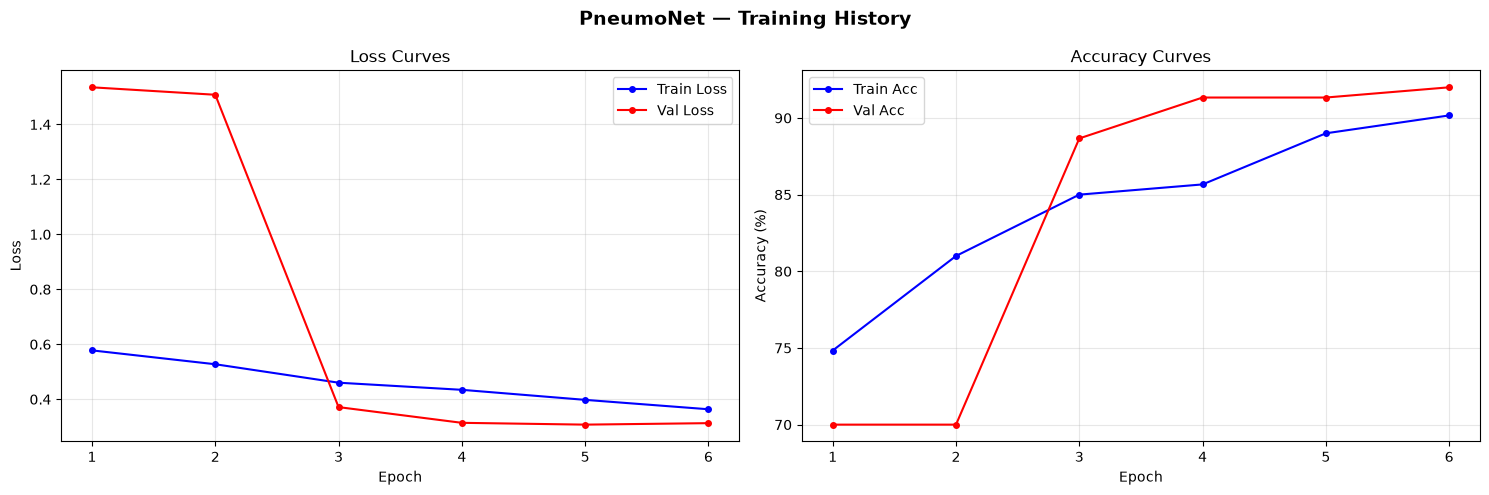

Saved → results\PneumoNet_curves.png



  PneumoNet — Test Set Results
  Accuracy : 80.45%
  F1 Score : 79.00%
  AUC-ROC  : 0.9123

  Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.9058    0.5342    0.6720       234
   PNEUMONIA     0.7757    0.9667    0.8607       390

    accuracy                         0.8045       624
   macro avg     0.8408    0.7504    0.7664       624
weighted avg     0.8245    0.8045    0.7900       624



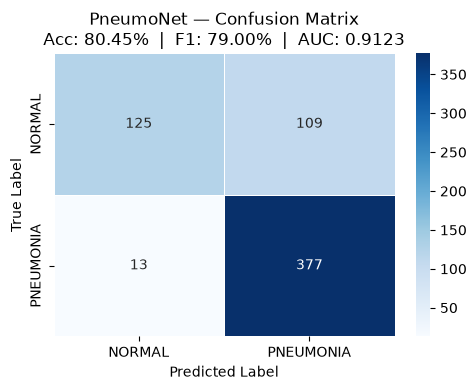

  Confusion matrix saved → results\PneumoNet_confusion_matrix.png


In [15]:
# ╔══════════════════════════════════════════════════════════════╗
# ║          SET YOUR DATASET PATHS HERE                         ║
# ╚══════════════════════════════════════════════════════════════╝

GASTRO_DIR  = "datasets/hyperkvasir"
PNEUMO_DIR  = r"chest_xray"
NEURO_DIR   = "datasets/brain_tumor_mri"

# ── Config ─────────────────────────────────────────────────────
BATCH_SIZE  = 32
NUM_EPOCHS  = 6
LR          = 3e-4

# ── PNEUMONET ──────────────────────────────────────────────────
if os.path.exists(PNEUMO_DIR):
    print("Loading Pneumonia dataset and configuring PneumoNet...")
    pneumo_train, pneumo_val, pneumo_test, pneumo_classes = \
        load_dataset(PNEUMO_DIR, batch_size=BATCH_SIZE, num_workers=0)
    
    ckpt_path = os.path.join("checkpoints", "PneumoNet_best.pth")
    if os.path.exists(ckpt_path):
        print(f"Loading trained checkpoint from {ckpt_path}...")
        pneumo_model, pneumo_history = load_checkpoint(ckpt_path)
    else:
        pneumo_model = PneumoNet()
        pneumo_model, pneumo_history = train_model(
            pneumo_model, pneumo_train, pneumo_val,
            num_epochs=NUM_EPOCHS, lr=LR)
    
    if pneumo_history:
        plot_history(pneumo_history, "PneumoNet")
    pneumo_metrics = evaluate_model(pneumo_model, pneumo_test, pneumo_classes)


## 🔥 Step 13 — Run Grad-CAM on a Single Image

Running Grad-CAM on: chest_xray\test\PNEUMONIA\person100_bacteria_475.jpeg



  [PneumoNet]
  Prediction : NORMAL
  Confidence : 85.19%
  Class idx  : 0


Saved → results\PneumoNet_gradcam_person100_bacteria_475.jpeg


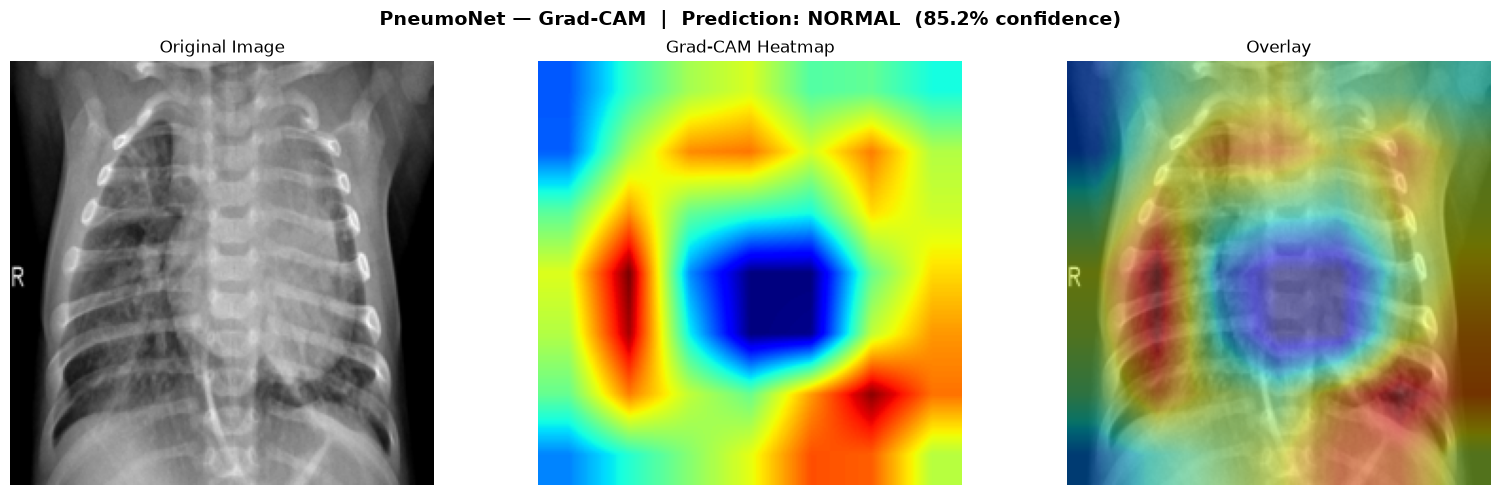

In [16]:
# ── Step 13: Run Grad-CAM on a test image ──────────────────────
import glob

test_samples = glob.glob(os.path.join(PNEUMO_DIR, "test", "PNEUMONIA", "*.*"))
if not test_samples:
    test_samples = glob.glob(os.path.join(PNEUMO_DIR, "chest_xray", "test", "PNEUMONIA", "*.*"))

if test_samples and 'pneumo_model' in locals():
    IMAGE_PATH = test_samples[0]
    CLASS_NAMES = pneumo_classes
    print(f"Running Grad-CAM on: {IMAGE_PATH}")
    pred, conf, heatmap = predict_single(pneumo_model, IMAGE_PATH, CLASS_NAMES)


## 💾 Step 14 — Save and Load Checkpoints

Loaded PneumoNet from checkpoints\PneumoNet_best.pth ✓


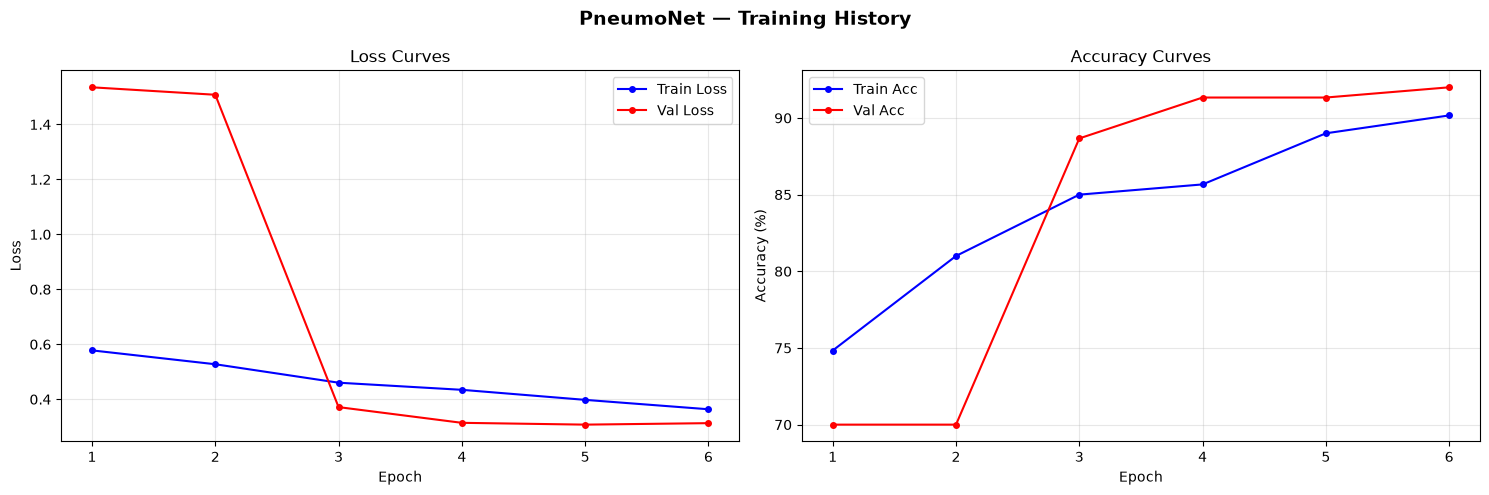

Saved → results\PneumoNet_curves.png


In [17]:
# ── Step 14: Save and Load Checkpoints ──────────────────────────
ckpt_path = os.path.join("checkpoints", "PneumoNet_best.pth")
if os.path.exists(ckpt_path):
    model, history = load_checkpoint(ckpt_path)
    if history:
        plot_history(history, model.model_name)


## ✅ Summary

### Architecture Built

```
Input (224×224)
    ↓
┌───────────────┬────────────────┐
│  Path A (3×3) │  Path B (5×5)  │
│  fine details │  big patterns  │
└───────┬───────┴────────┬───────┘
        └────────┬────────┘
              JOIN
            (concat)
               ↓
         CBAM Attention
       (Channel + Spatial)
               ↓
        Decision Layers
         FC → Dropout
               ↓
          Prediction
               ↓
         Grad-CAM Heatmap
```

### Models

| Model | Disease | Classes | Parameters |
|-------|---------|---------|-----------|
| GastroNet | Gastric Ulcer | Ulcer / Normal | ~9.6M |
| PneumoNet | Pneumonia | Normal / Pneumonia | ~9.6M |
| NeuroNet | Brain Tumor | Glioma / Meningioma / Pituitary / No Tumor | ~9.6M |

### Quick Start
```python
# 1. Load data
train_loader, val_loader, test_loader, class_names = load_dataset("your/dataset/path")

# 2. Pick model
model = GastroNet()   # or PneumoNet() / NeuroNet()

# 3. Train
model, history = train_model(model, train_loader, val_loader)

# 4. Evaluate
evaluate_model(model, test_loader, class_names)

# 5. Grad-CAM on any image
predict_single(model, "image.jpg", class_names)
```
